### Battery life model library
Example notebook demonstrating impact of module architecture and cell voltage window on module level energy density and specific energy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

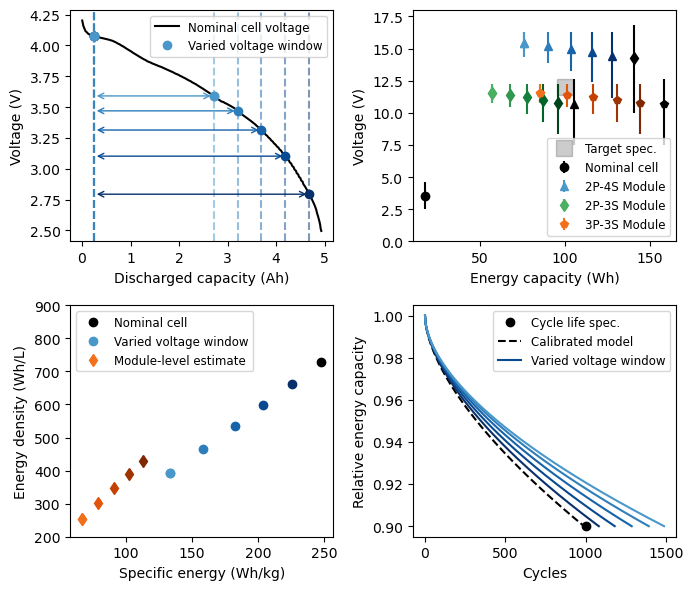

In [2]:
cap = np.array([
    0.000952536, 0.005538524, 0.010917151, 0.014472706, 0.020538827, 0.026537007, 0.033162535, 0.040079015,
    0.047742899, 0.054625573, 0.061759331, 0.068893089, 0.076026846, 0.083160604, 0.090294362, 0.09742812,
    0.104561878, 0.111695636, 0.118829394, 0.125963152, 0.132919674, 0.1400042, 0.147332579, 0.154591895,
    0.161754612, 0.169105403, 0.175613392, 0.183075679, 0.190200944, 0.197300732, 0.204765011, 0.211568248,
    0.218710498, 0.225835764, 0.233070514, 0.240296084, 0.247475748, 0.254568955, 0.261504553, 0.268772405,
    0.27553099, 0.282552536, 0.290180152, 0.297458694, 0.304193867, 0.311237038, 0.318659543, 0.325708375,
    0.332694436, 0.339798655, 0.346952863, 0.354125818, 0.361664606, 0.368393333, 0.375400095, 0.382909937,
    0.389997122, 0.396734561, 0.404147866, 0.411407182, 0.418564001, 0.425627842, 0.433024474, 0.439568747,
    0.447004907, 0.453985364, 0.461495117, 0.468648927, 0.475525785, 0.482364985, 0.489859377, 0.496652313,
    0.504052324, 0.511103228, 0.518588026, 0.525572494, 0.532587356, 0.539721114, 0.546772018, 0.553731781,
    0.560782685, 0.567833589, 0.574609506, 0.581844256, 0.589140481, 0.5962353, 0.602892239, 0.610379288,
    0.617636574, 0.624977326, 0.631780562, 0.638489691, 0.64443449, 0.651143619, 0.658277377, 0.665411135,
    0.672544893, 0.679678651, 0.686729555, 0.693689319, 0.700657368, 0.707617132, 0.714300789, 0.720470526,
    0.726869791, 0.733039528, 0.739330456, 0.745037462, 0.751139759, 0.756327947, 0.762481199, 0.768425997,
    0.774615581, 0.780070808, 0.786129143, 0.791317331, 0.797419628, 0.803126634, 0.809200944, 0.814105403,
    0.820071432, 0.824975891, 0.830941921, 0.835846379, 0.841784808, 0.846065063, 0.851975891, 0.856256146,
    0.862169317, 0.866105183, 0.872035339, 0.875602218, 0.881575325, 0.884745884, 0.890747299, 0.893917859,
    0.899919274, 0.903089833, 0.909091248, 0.912152928, 0.918489691, 0.925283747, 0.93192583, 0.938192452,
    0.944239161, 0.950020284, 0.955462502, 0.960527908, 0.96502897, 0.968425997, 0.9723271, 0.975681078,
    0.9787608, 0.981504553, 0.983252379, 0.985968248
])
voltage = np.array([
    4.201933606, 4.158154638, 4.133656051, 4.115885988, 4.105402725, 4.092910617, 4.087172565, 4.08138187,
    4.076990784, 4.07332754, 4.069247733, 4.065746995, 4.062272578, 4.059192981, 4.056139706, 4.052981145,
    4.049664656, 4.046058632, 4.042005146, 4.037188341, 4.030872364, 4.024688995, 4.015683806, 4.009279552,
    4.000114734, 3.992552135, 3.983857151, 3.974600801, 3.966047024, 3.95661872, 3.948218656, 3.938799173,
    3.930090758, 3.920900662, 3.912812897, 3.904282649, 3.896066123, 3.888060404, 3.881918758, 3.872362034,
    3.866334827, 3.861400747, 3.85351894, 3.848311672, 3.842765765, 3.836416532, 3.830697431, 3.826486017,
    3.819962902, 3.814195096, 3.807042646, 3.800749821, 3.794286919, 3.788164171, 3.782313545, 3.773811922,
    3.767657823, 3.762801535, 3.753681191, 3.747276937, 3.73941338, 3.733057968, 3.724499341, 3.717037241,
    3.710456287, 3.701028388, 3.693170625, 3.686245919, 3.676932113, 3.668848899, 3.659471339, 3.651109065,
    3.641631248, 3.632292308, 3.623756288, 3.614430118, 3.604570802, 3.594331801, 3.584486336, 3.574065011,
    3.564207027, 3.55409867, 3.545235388, 3.542031299, 3.533086621, 3.527054456, 3.519758181, 3.512051293,
    3.503638036, 3.494965186, 3.485440418, 3.475096132, 3.461738052, 3.452209727, 3.441983887, 3.432047581,
    3.422558738, 3.411924917, 3.402106415, 3.391145824, 3.380616646, 3.369224642, 3.359108659, 3.346963139,
    3.33722282, 3.323912048, 3.314657038, 3.301454254, 3.292287249, 3.277647799, 3.268276205, 3.2538894,
    3.243836067, 3.229529645, 3.220496992, 3.205606292, 3.196274181, 3.181381567, 3.171792867, 3.156747754,
    3.14788651, 3.131770448, 3.122183722, 3.1061713, 3.096445236, 3.079439018, 3.06993175, 3.052262235,
    3.041817836, 3.023272184, 3.013196102, 2.994106551, 2.983518792, 2.964459217, 2.954775889, 2.935245455,
    2.92492749, 2.905397056, 2.895079091, 2.87523685, 2.858215396, 2.834861788, 2.811871102, 2.788398701,
    2.765478078, 2.741967858, 2.718045156, 2.694102501, 2.669423208, 2.640615346, 2.616874417, 2.592969334,
    2.569078163, 2.544222213, 2.51636341, 2.496201298
])
cap = cap*5

dods = [0.9, 0.8, 0.7, 0.6, 0.5]
cmap = plt.get_cmap('Blues')
norm = plt.Normalize(vmin=-0.1, vmax=max(dods))

fig, ax = plt.subplots(2, 2, figsize=(7,6))
ax = ax.ravel()

ax[0].plot(cap, voltage, '-k', label='Nominal cell voltage')
for dod in dods:
    socs = np.array([0.95, (1 - dod)-0.05])
    caps = np.interp(1-socs, cap/max(cap), cap)
    v_window = np.interp(caps, cap, voltage)
    ax[0].plot(caps, v_window, 'o', color=cmap(norm(dod)))
    ax[0].axvline(caps[0], ymin=0, ymax=1, color=cmap(norm(dod)), linestyle='--', alpha=0.5)
    ax[0].axvline(caps[1], ymin=0, ymax=1, color=cmap(norm(dod)), linestyle='--', alpha=0.5)
    ax[0].annotate("", xytext=(caps[0], v_window[1]), xy=(caps[1], v_window[1]),
            arrowprops=dict(arrowstyle="<->", color=cmap(norm(dod))))
ax[0].plot(caps, v_window, 'o', color=cmap(norm(dod)), label='Varied voltage window')
ax[0].set_xticks(np.arange(0, 6, 1))
ax[0].set_xlabel('Discharged capacity (Ah)')
ax[0].set_ylabel('Voltage (V)')
ax[0].legend(loc='upper right', fontsize=8.5)

avg_voltage = np.trapz(voltage, cap) / max(cap)
v_window = np.expand_dims(np.array([avg_voltage-min(voltage)], max(voltage)-avg_voltage), axis=1)
energy = np.trapz(voltage, cap)

ax[1].plot(100, 12, 'sk', label='Target spec.', markersize=12, alpha=0.2)
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='ok', label='Nominal cell')
n_series = 4
n_parallel = 2
voltage_pack = voltage * n_series
cap_pack = cap * n_parallel
avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
energy = np.trapz(voltage_pack, cap_pack)
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='dk')
for dod in dods:
    socs = np.array([0.95, (1 - dod)-0.05])
    caps = np.interp(1-socs, cap/max(cap), cap)
    v_window = np.interp(caps, cap, voltage)
    idx_start = np.argmin(np.abs(voltage - v_window[0]))
    idx_end = np.argmin(np.abs(voltage - v_window[1]))
    voltage_dod = voltage[idx_start:idx_end+1]
    cap_dod = cap[idx_start:idx_end+1]
    voltage_pack = voltage_dod * n_series
    cap_pack = (cap_dod-min(cap_dod)) * n_parallel
    avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
    v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
    energy = np.trapz(voltage_pack, cap_pack)
    ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='^', color=cmap(norm(dod)))
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='^', color=cmap(norm(dod)), label=f'{n_parallel}P-{n_series}S Module')

n_series = 3
n_parallel = 2
voltage_pack = voltage * n_series
cap_pack = cap * n_parallel
avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
energy = np.trapz(voltage_pack, cap_pack)
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='^k')
cmap2 = plt.get_cmap('Greens')
for dod in dods:
    socs = np.array([0.95, (1 - dod)-0.05])
    caps = np.interp(1-socs, cap/max(cap), cap)
    v_window = np.interp(caps, cap, voltage)
    idx_start = np.argmin(np.abs(voltage - v_window[0]))
    idx_end = np.argmin(np.abs(voltage - v_window[1]))
    voltage_dod = voltage[idx_start:idx_end+1]
    cap_dod = cap[idx_start:idx_end+1]
    voltage_pack = voltage_dod * n_series
    cap_pack = (cap_dod-min(cap_dod)) * n_parallel
    avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
    v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
    energy = np.trapz(voltage_pack, cap_pack)
    ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='d', color=cmap2(norm(dod)))
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='d', color=cmap2(norm(dod)), label=f'{n_parallel}P-{n_series}S Module')

n_series = 3
n_parallel = 3
voltage_pack = voltage * n_series
cap_pack = cap * n_parallel
avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
energy = np.trapz(voltage_pack, cap_pack)
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='pk')
cmap3 = plt.get_cmap('Oranges')
for dod in dods:
    socs = np.array([0.95, (1 - dod)-0.05])
    caps = np.interp(1-socs, cap/max(cap), cap)
    v_window = np.interp(caps, cap, voltage)
    idx_start = np.argmin(np.abs(voltage - v_window[0]))
    idx_end = np.argmin(np.abs(voltage - v_window[1]))
    voltage_dod = voltage[idx_start:idx_end+1]
    cap_dod = cap[idx_start:idx_end+1]
    voltage_pack = voltage_dod * n_series
    cap_pack = (cap_dod-min(cap_dod)) * n_parallel
    avg_voltage = np.trapz(voltage_pack, cap_pack) / max(cap_pack)
    v_window = np.expand_dims(np.array([avg_voltage-min(voltage_pack), max(voltage_pack)-avg_voltage]), axis=1)
    energy = np.trapz(voltage_pack, cap_pack)
    ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='p', color=cmap3(norm(dod)))
ax[1].errorbar(energy, avg_voltage, yerr=v_window, fmt='p', color=cmap3(norm(dod)),  label=f'{n_parallel}P-{n_series}S Module')
ax[1].set_xlabel('Energy capacity (Wh)')
ax[1].set_ylabel('Voltage (V)')
ax[1].legend(loc='lower right', fontsize=8.5)
ax[1].set_ylim(0, 18)

from blast.models.nca_gr_Panasonic3Ah_2018 import Nca_Gr_Panasonic3Ah_Battery
hours = np.arange(6)
soc = np.array([1., 0.5, 0.,
                0., 0.5, 1.])
T_C = np.full_like(soc, 30)
input = {"Time_s": hours * 3600, "SOC": soc, "Temperature_C": T_C}
batt = Nca_Gr_Panasonic3Ah_Battery(degradation_scalar=1.5)
batt.simulate_battery_life(input, is_constant_input=True, threshold_capacity=0.9)

batt_dod = []
for dod in dods:
    upper_soc = 1-(1-dod)
    lower_soc = 0
    soc = np.array([upper_soc, 0.5, lower_soc,
                    lower_soc, 0.5, upper_soc,])
    T_C = np.full_like(soc, 30)
    input = {"Time_s": hours * 3600, "SOC": soc, "Temperature_C": T_C}
    batt_ = Nca_Gr_Panasonic3Ah_Battery(degradation_scalar=1.5)
    batt_.simulate_battery_life(input, is_constant_input=True, threshold_capacity=0.9)
    batt_dod.append(batt_)

cell_weight = 71/1000
cell_vol = 0.0242
energy = np.trapz(voltage, cap)
ax[2].plot(energy/cell_weight, energy/cell_vol, 'ok', label='Nominal cell')
for dod in dods:
    socs = np.array([0.95, (1 - dod)-0.05])
    caps = np.interp(1-socs, cap/max(cap), cap)
    v_window = np.interp(caps, cap, voltage)
    idx_start = np.argmin(np.abs(voltage - v_window[0]))
    idx_end = np.argmin(np.abs(voltage - v_window[1]))
    voltage_dod = voltage[idx_start:idx_end+1]
    cap_dod = cap[idx_start:idx_end+1]
    energy = np.trapz(voltage_dod, cap_dod)
    ax[2].plot(energy/cell_weight, energy/cell_vol, 'o', color=cmap(norm(dod)))
    ax[2].plot(0.5 * energy/cell_weight, 0.65*energy/cell_vol, 'd', color=cmap3(norm(dod)))
ax[2].plot(energy/cell_weight, energy/cell_vol, 'o', color=cmap(norm(dod)), label='Varied voltage window')
ax[2].plot(0.5 * energy/cell_weight, 0.65*energy/cell_vol, 'd', color=cmap3(norm(dod)), label='Module-level estimate')
ax[2].set_xlabel('Specific energy (Wh/kg)')
ax[2].set_ylabel('Energy density (Wh/L)')
ax[2].legend(loc='upper left', fontsize=8.5)
ax[2].set_ylim(200, 900)

idx = 3
ax[idx].plot(1000, 0.9, 'ok', label='Cycle life spec.')
ax[idx].plot(batt.stressors['efc'], batt.outputs['q'], '--k', label='Calibrated model')
for i, dod in enumerate(dods):
    if i == 1:
        ax[idx].plot(batt_dod[i].stressors['efc'], batt_dod[i].outputs['q'], color=cmap(norm(dod)), label='Varied voltage window')
    else:
        ax[idx].plot(batt_dod[i].stressors['efc'], batt_dod[i].outputs['q'], color=cmap(norm(dod)))
ax[idx].set_ylabel('Relative energy capacity')
ax[idx].set_xlabel('Cycles')
ax[idx].set_xticks(np.arange(0, 1501, 500))
ax[idx].legend(loc='upper right', fontsize=8.5)


fig.tight_layout()